In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Charger le CSV en précisant qu'il faut ignorer les virgules dans les guillemets
df = pd.read_csv('../data/Student_Dataset.csv', header=None, engine='python', on_bad_lines='skip')

print("Dimensions du fichier :", df.shape)
df.head()

Dimensions du fichier : (397, 2)


,0,1
0,1,On uneven paths the heel feels wobbly side‑to‑...
1,4,A short sprint brought on a twinge in the midd...
2,6,A sudden twist while reaching for a bag made o...
3,8,I noticed a rash on my forearms after handling...
4,11,I feel an unexplained pressure behind my eyes ...


In [5]:
import csv
import pandas as pd

# Path vers le fichier Student_Dataset.csv
file_path = '../data/Student_Dataset.csv'

rows = []
with open(file_path, 'r', encoding='utf-8') as f:
    reader = csv.reader(f)
    for line in reader:
        if not line:
            continue
        # Cas à 3 éléments : ID, Couleur, Témoignage
        if len(line) == 3:
            rows.append({'id': line[0], 'color': line[1], 'text': line[2]})
        # Cas à 2 éléments : ID, Témoignage (sans couleur)
        elif len(line) == 2:
            rows.append({'id': line[0], 'color': '#000000', 'text': line[1]})

# Création du DataFrame propre
data = pd.DataFrame(rows)

# Nettoyage et formatage du DataFrame
data['text'] = data['text'].fillna('')
data = data[data['text'].str.strip() != '']

print(f"Nombre de témoignages correctement chargés : {len(data)}")
data.head()

Nombre de témoignages correctement chargés : 1011


,id,color,text
0,﻿1,#000000,On uneven paths the heel feels wobbly side‑to‑...
1,2,0x000000,"The feverish feeling eased, but I’m now breath..."
2,3,0x000000,"While working in the garden, I touched a metal..."
3,4,#000000,A short sprint brought on a twinge in the midd...
4,5,0x000000,I accidentally left my hand on a hot mug for a...


In [8]:
import re
from sklearn.feature_extraction.text import TfidfVectorizer

# 1. Fonction de nettoyage de texte
def clean_text(text):
    text = str(text).lower() # Passer en minuscules
    text = re.sub(r'[^a-zA-Z\s]', '', text) # Supprimer la ponctuation et les chiffres
    text = re.sub(r'\s+', ' ', text).strip() # Enlever les espaces multiples
    return text

data['cleaned_text'] = data['text'].apply(clean_text)

# 2. Vectorisation TF-IDF (suppression des stop-words anglais)
vectorizer = TfidfVectorizer(stop_words='english', max_features=500)
X = vectorizer.fit_transform(data['cleaned_text'])

print("Prétraitement NLP et vectorisation terminés !")
print(f"Forme de la matrice TF-IDF : {X.shape}")

Prétraitement NLP et vectorisation terminés !
Forme de la matrice TF-IDF : (1011, 500)


In [9]:
import re
from sklearn.feature_extraction.text import TfidfVectorizer

# 1. Fonction de nettoyage : minuscules + suppression ponctuation & chiffres
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

# Application du nettoyage
data['cleaned_text'] = data['text'].apply(clean_text)

# 2. Vectorisation TF-IDF (retrait des stop-words anglais)
vectorizer = TfidfVectorizer(stop_words='english', max_features=500)
X = vectorizer.fit_transform(data['cleaned_text'])

print("Prétraitement et vectorisation terminés !")
print(f"Forme de la matrice TF-IDF (témoignages x mots-clés) : {X.shape}")

Prétraitement et vectorisation terminés !
Forme de la matrice TF-IDF (témoignages x mots-clés) : (1011, 500)


Score de Silhouette pour 5 clusters : 0.0196


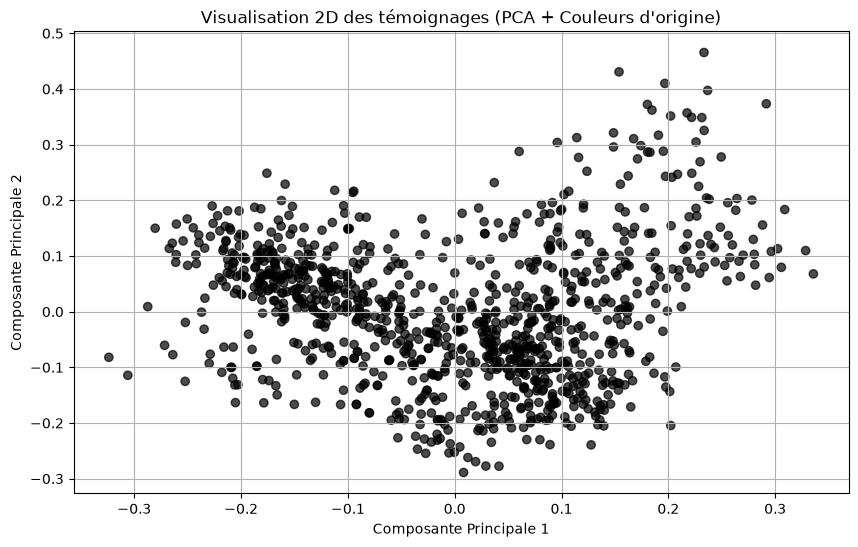

In [10]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# 1. Entraînement de K-Means (ex: 5 clusters)
n_clusters = 5
kmeans = KMeans(n_clusters=n_clusters, random_state=42)
data['cluster'] = kmeans.fit_predict(X)

# 2. Score de Silhouette (pour évaluer la qualité du clustering)
score = silhouette_score(X, data['cluster'])
print(f"Score de Silhouette pour {n_clusters} clusters : {score:.4f}")

# 3. Réduction de dimension 2D avec PCA
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X.toarray())

# 4. Formatage des couleurs (conversion 0x -> #)
hex_colors = data['color'].astype(str).str.replace('0x', '#')

# 5. Affichage du graphique 2D
plt.figure(figsize=(10, 6))
plt.scatter(X_2d[:, 0], X_2d[:, 1], c=hex_colors, alpha=0.7, edgecolors='k')
plt.title("Visualisation 2D des témoignages (PCA + Couleurs d'origine)")
plt.xlabel("Composante Principale 1")
plt.ylabel("Composante Principale 2")
plt.grid(True)
plt.show()

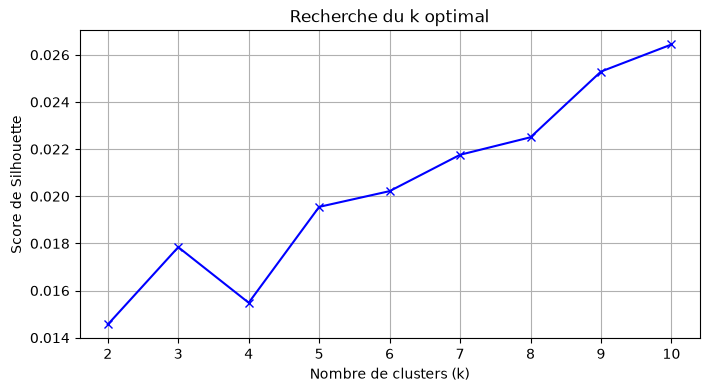

In [11]:
scores = []
K_range = range(2, 11)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42)
    labels = km.fit_predict(X)
    scores.append(silhouette_score(X, labels))

plt.figure(figsize=(8, 4))
plt.plot(K_range, scores, 'bx-')
plt.xlabel('Nombre de clusters (k)')
plt.ylabel('Score de Silhouette')
plt.title('Recherche du k optimal')
plt.grid(True)
plt.show()

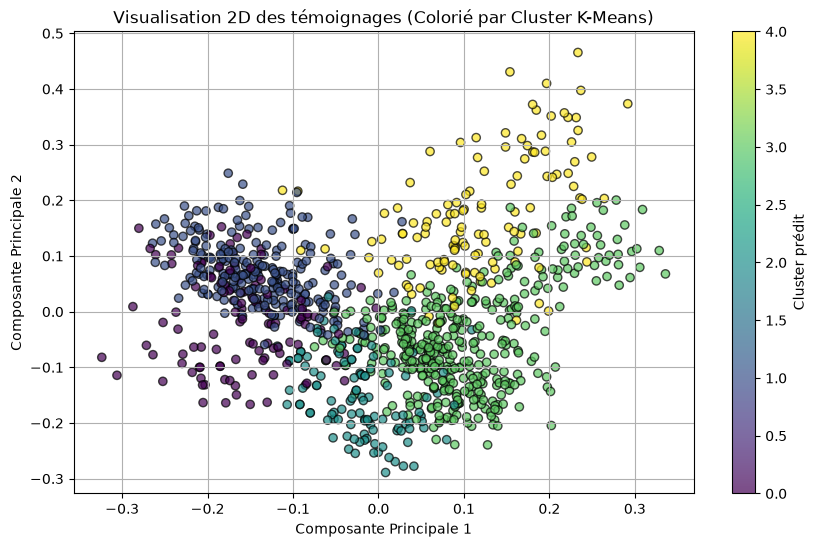

In [12]:
plt.figure(figsize=(10, 6))
plt.scatter(X_2d[:, 0], X_2d[:, 1], c=data['cluster'], cmap='viridis', alpha=0.7, edgecolors='k')
plt.colorbar(label='Cluster prédit')
plt.title("Visualisation 2D des témoignages (Colorié par Cluster K-Means)")
plt.xlabel("Composante Principale 1")
plt.ylabel("Composante Principale 2")
plt.grid(True)
plt.show()

In [13]:
words = vectorizer.get_feature_names_out()
for i in range(n_clusters):
    cluster_center = kmeans.cluster_centers_[i]
    top_indices = cluster_center.argsort()[-5:][::-1]
    top_words = [words[idx] for idx in top_indices]
    print(f"Cluster {i} : {', '.join(top_words)}")

Cluster 0 : hot, blister, feels, hand, skin
Cluster 1 : makes, ache, deep, theres, shoulder
Cluster 2 : itchy, rash, new, spots, bumps
Cluster 3 : feel, cough, im, ive, chest
Cluster 4 : pain, ear, head, feel, throbbing
